# Generate images

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler


#%% Loading the data
df = pd.read_csv("dataset.csv")

# Control NaN values
df = df.drop(columns = ['src_ip', 'Label'], axis = 1)
df.replace([np.inf, -np.inf], np.nan, inplace=True)  # Replace infinity with NaN
df.fillna(df.max(), inplace=True)
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)


In [1]:
import numpy as np

def arrange_image_square(row, image_size):
    # Create an empty matrix for the single-channel image
    image = np.zeros((image_size, image_size))

    # Fill the image row by row
    for i in range(image_size):
        for j in range(image_size):
            index = i * image_size + j
            if index < len(row):
                image[i, j] = row.iloc[index] * 255

    return image


Index: 0


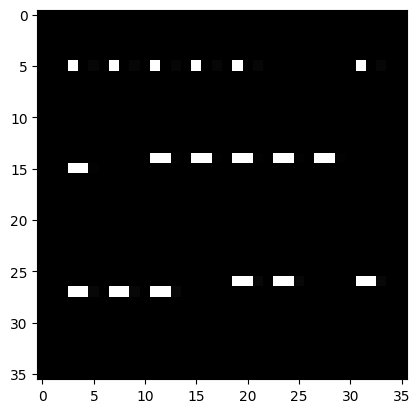

Index: 100


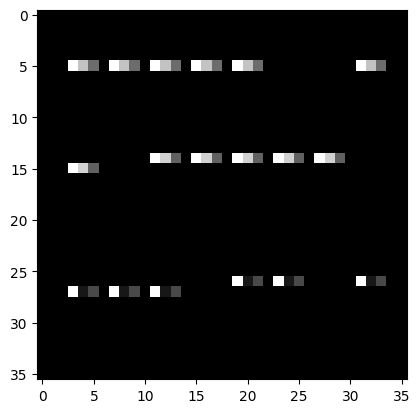

Index: 200


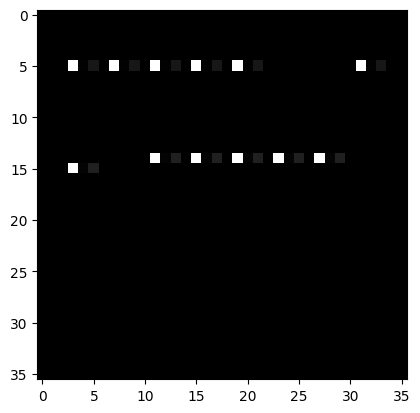

Index: 300


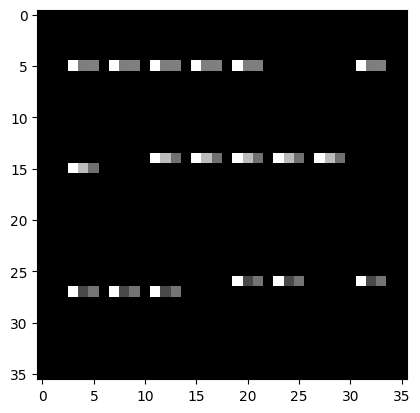

Index: 400


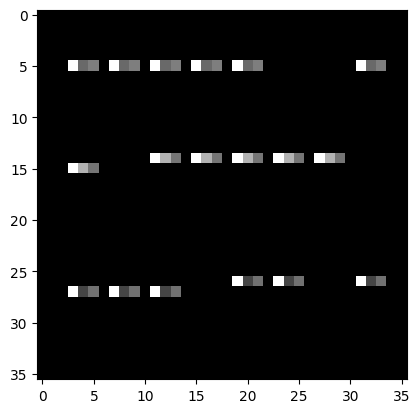

In [3]:

import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler



# Step 4: Generate images and print index and image if index % 40 is 0
image_size = 36  # Example size, adjust as needed
images = [] 
for index, row in df.iterrows():
    image = arrange_image_square(row, image_size)
    images.append(image)
    if index % 100 == 0:
        print(f"Index: {index}")
        plt.imshow(image, cmap='gray')
        plt.show()

images = np.array(images)

# Step 5: Replicate the single-channel images across three channels
images_rgb = np.repeat(images[..., np.newaxis], 3, -1)

# Normalize images
scaler = MinMaxScaler()
images_rgb = scaler.fit_transform(images_rgb.reshape(-1, images_rgb.shape[-1])).reshape(images_rgb.shape)

In [4]:
images_rgb[0].shape

(36, 36, 3)

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df2 = pd.read_csv("dataset.csv")

# Change label from 'Suspicious' to 'Critical'
df2["Label"] = df2["Label"].apply(lambda x: "Critical" if x == "Suspicious" else x) 

if os.path.exists('img') and os.listdir('img'):
    print("Directory is not empty. Exiting...")
else:  
    for index, row in df2.iterrows():
        label = row['Label']
        src_ip = row['src_ip']
        image = images_rgb[index]

        # Create directory if it doesn't exist
        directory = f"img/{label}"
        if not os.path.exists(directory):
            os.makedirs(directory)
        
        # Save the image using plt.imsave
        file_path = os.path.join(directory, f"{src_ip}.png")
        plt.imsave(file_path, image)

    print("Images saved successfully.")


Images saved successfully.


# Run training

# Fitting a CNN Model

In [18]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import torch.nn.functional as F

In [19]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        # Reduced pooling size to preserve more information
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout1 = nn.Dropout(0.25)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.dropout2 = nn.Dropout(0.25)
        # Additional convolutional layer to capture more complex patterns
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.dropout3 = nn.Dropout(0.25)
        # Batch normalization to stabilize learning
        self.bn1 = nn.BatchNorm2d(16)
        self.bn2 = nn.BatchNorm2d(32)
        self.bn3 = nn.BatchNorm2d(64)
        # Adjusted for an additional pooling layer, resulting in 36/2/2/2 = 4.5 ~ 4 (floor) for the size of feature maps
        self.fc1 = nn.Linear(64 * 4 * 4, 256)  # Adjusted for added complexity and reduced pooling effect
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.dropout1(x)
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.dropout2(x)
        x = self.pool(F.relu(self.bn3(self.conv3(x))))  # Additional pooling layer for the new conv layer
        x = self.dropout3(x)
        x = x.view(x.size(0), -1)  # Flatten the tensor for the fully connected layer
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [21]:
import numpy as np
from sklearn.model_selection import train_test_split

y = df2["Label"]
 
X_train, X_test, y_train, y_test = train_test_split(images_rgb, y, test_size=0.2, random_state=42)

In [22]:
from sklearn.preprocessing import LabelEncoder
from collections import Counter
# from sklearn.model_selection import train_test_split
import numpy as np

#y = df["Label"]
# Add stratify=y to ensure the same distribution of classes in both sets
#X_train, X_test, y_train, y_test = train_test_split(X_REFINED_MDS, y, test_size=0.2, random_state=42, stratify=y)

#y_train = y_train.values
#y_test = y_test.values

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = np.unique(y_train_enc).size

print(Counter(y_train_enc))
print(Counter(y_test_enc))

Counter({0: 170, 1: 162})
Counter({0: 55, 1: 29})


In [35]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
preprocess = transforms.Compose([
    transforms.ToTensor()
])
X_train_tensor = torch.tensor(X_train[:,:,:,0], dtype=torch.float).unsqueeze(1)  # Selects the first channel and adds a channel dimension
y_train_tensor = torch.from_numpy(le.fit_transform(y_train))

X_test_tensor = torch.tensor(X_test[:,:,:,0], dtype=torch.float).unsqueeze(1)  # Selects the first channel and adds a channel dimension
y_test_tensor = torch.from_numpy(le.transform(y_test))

cuda


In [36]:
batch_size = 32

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [37]:
model = SimpleCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-03,
    weight_decay=1e-05
)

In [38]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device).long()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 1.079
[20] loss: 0.634
[40] loss: 0.633
[60] loss: 0.601
[80] loss: 0.570
[99] loss: 0.569


In [39]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 0.681
The test accuracy was 0.655


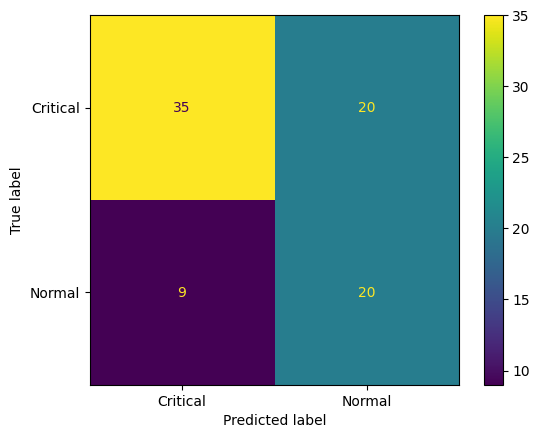

In [40]:
_ = ConfusionMatrixDisplay.from_predictions(y_test_tensor, test_predicted, display_labels=le.classes_)

## Fastai

In [7]:
from fastai.vision.all import *

# Step 1: Define the DataBlock
datablock = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(36)  # Resize images to 36x36 if necessary
)

# Step 2: Create a DataLoader
dls = datablock.dataloaders('img')


## Resnet 18

In [9]:

# Step 3: Load a Pretrained ResNet18 Model
learn = cnn_learner(dls, resnet18, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)

epoch,train_loss,valid_loss,accuracy,time
0,1.180093,0.965726,0.506024,00:00
1,1.092932,0.746380,0.385542,00:00
2,0.996540,0.737299,0.481928,00:00
3,0.967700,0.931341,0.506024,00:00
4,0.918040,1.026443,0.493976,00:00
5,0.903391,1.895896,0.457831,00:00
6,0.879537,3.765553,0.433735,00:00
7,0.851820,7.091496,0.445783,00:00
8,0.839774,6.059252,0.469880,00:00
9,0.820137,6.250698,0.469880,00:00


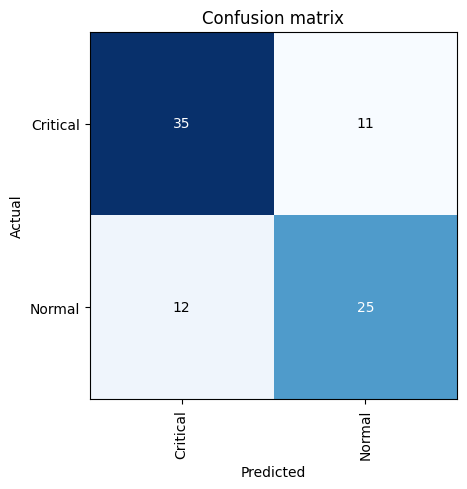

In [10]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

## Resnet 50

In [11]:
# Step 3: Load a Pretrained Model
learn = cnn_learner(dls, resnet50, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)

c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.364821,0.757398,0.578313,00:01
1,1.262697,2.051177,0.445783,00:00
2,1.263459,1.789190,0.433735,00:00
3,1.204447,1.384062,0.445783,00:00
4,1.163937,1.766879,0.445783,00:00
5,1.111426,1.328382,0.506024,00:00
6,1.092541,1.324875,0.542169,00:00
7,1.059887,1.449426,0.469880,00:01
8,1.051546,1.215661,0.506024,00:00
9,1.023577,1.128058,0.469880,00:00


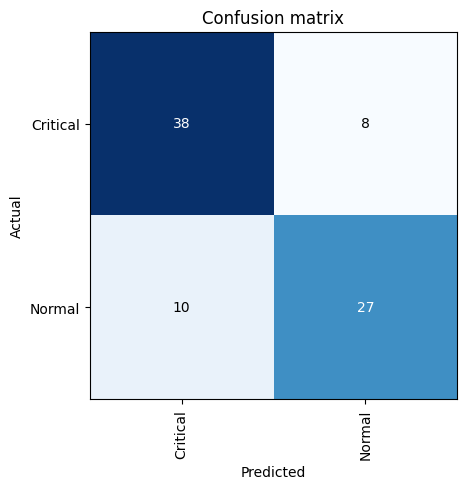

In [12]:


interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

## Resnet 101

In [13]:
# Step 3: Load a Pretrained Model
learn = cnn_learner(dls, resnet101, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)


c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.223217,1.763992,0.457831,00:01
1,1.199942,1.274296,0.433735,00:01
2,1.152081,1.492409,0.445783,00:01
3,1.121740,1.077900,0.397590,00:01
4,1.098529,1.037290,0.457831,00:01
5,1.097974,1.201778,0.421687,00:01
6,1.086261,1.922495,0.481928,00:01
7,1.102172,1.980229,0.530120,00:01
8,1.091659,2.433902,0.409639,00:01
9,1.097616,3.388884,0.481928,00:01


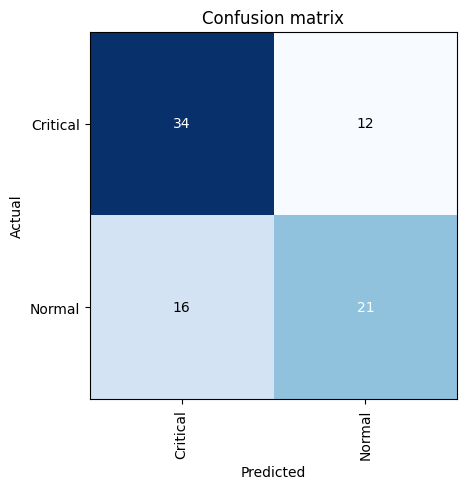

In [14]:

interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

## Resnet 152

In [15]:
# Step 3: Load a Pretrained Model
learn = cnn_learner(dls, resnet152, metrics=accuracy)

# Step 4: Train the Model
learn.fit_one_cycle(25)


c:\Python312\Lib\site-packages\fastai\vision\learner.py:301: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,accuracy,time
0,1.122487,0.745200,0.578313,00:01
1,1.183265,1.314565,0.554217,00:01
2,1.156771,0.821920,0.481928,00:01
3,1.097062,1.165308,0.469880,00:01
4,1.056389,0.926854,0.530120,00:01
5,1.037713,1.032662,0.518072,00:01
6,1.023921,0.901919,0.650602,00:01
7,1.002083,1.367160,0.602410,00:01
8,1.027742,2.238868,0.554217,00:01
9,1.004404,1.442859,0.578313,00:01


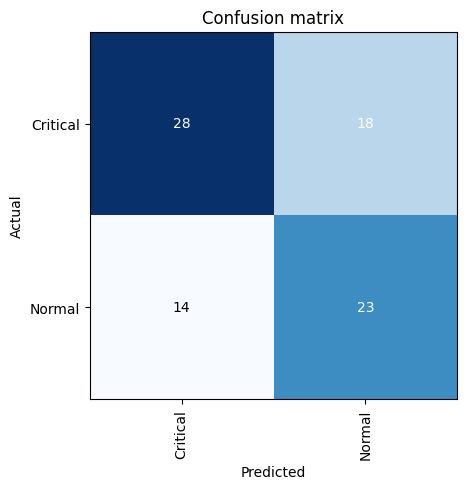

In [16]:

interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()